In [1]:
!pip install tensorflow==2.21.0
!pip install keras==3.12.1

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.6/572.6 MB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 84.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 324.3/324.3 kB 21.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.6/572.6 MB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 84.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 324.3/324.3 kB 21.7 MB/s eta 0:00:00
  Attempting uninstall: protobuf
    Found existing installation: protobuf 5.29.6
    Uninstalling protobuf-5.29.6:
  Attempting uninstall: protobuf
    Found existing installation: protobuf 5.29.6
    Uninstalling protobuf-5.29.6:
      Successfully uninstalled protobuf-5.29.6
      Successfully uninstalled protobuf-5.29.6
  Attempting uninstall: h5py
  Attempting uninstall: h5py
    Found existing installation: h5py 3.16.0
    Uninstalling h5py-3.16.0:
      Successfully uninstalled h5py-3.16.0
    Found existing ins

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/1.5 MB ? eta -:--:--Collecting keras==3.12.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 48.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 48.1 MB/s eta 0:00:00
  Attempting uninstall: keras
    Found existing installation: keras 3.13.2
    Uninstalling keras-3.13.2:
  Attempting uninstall: keras
    Found existing installation: keras 3.13.2
    Uninstalling keras-3.13.2:
      Successfully uninstalled keras-3.13.2
      Successfully uninstalled keras-3.13.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ydf-tf 2.20.0 requires tensorflow==2.20.0, but you have tensorflow 2.21.0 which is incompatible.
tf-keras 2.20.0 requires tensorflow<2.21,>=2.20, but you have tensorflow 2.21.0 which is incompatible.
tensorflow-text 2.20.1 requires tensorflow<2.21,>=2.20.0, but you have tenso

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from keras.models import Sequential, load_model, Model
from keras.optimizers import Adam
from keras.layers import  Dense, Flatten, Dropout, Rescaling, GlobalAveragePooling2D
from keras.preprocessing import image
from keras.applications import EfficientNetB0
from keras.applications import EfficientNetV2B0
from keras.applications.efficientnet import preprocess_input
from PIL import Image
from keras.utils import image_dataset_from_directory, plot_model
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

In [2]:
import tensorflow as tf
import keras
print(tf.__version__)
print(keras.__version__)
print(np.__version__)

2.21.0
3.12.1
2.0.2


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Data fetching and preprocessing

In [4]:
# the folder structure of the data should be:
# data/
#     class1/
#         img1.jpg
#         img2.jpg
#         ...
#     class2/
#         img1.jpg
#         img2.jpg
#         ...
#     ...


- visit this site for details of image_dataset_from_directory() : https://keras.io/api/data_loading/image/

In [5]:
batch_size = 64
img_height = 224
img_width = 224
data_dir = '/content/drive/MyDrive/Colab Notebooks/Projects/face_mask_detection/Dataset'
train_ds,val_test_ds = image_dataset_from_directory(
  data_dir,
  shuffle=True,
  labels = 'inferred',
  label_mode = 'int',
  validation_split=0.3, # large split taken beacuse val_test_ds is further divided into val_ds & test_ds
  subset="both", # if 'both' returns tuples of 2 dataset (train_ds,val_ds)
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size) # no. of data/imgs in each batch

Found 5988 files belonging to 2 classes.
Using 4192 files for training.
Using 1796 files for validation.


In [6]:
train_batches = train_ds.cardinality().numpy()  # total number of batches in train_ds
print(f"for training: {train_batches} batches")

val_test_batches = val_test_ds.cardinality().numpy()  # total number of batches in val_test_ds
print(f'for validation+tetsing: {val_test_batches} batches')

val_batches = val_test_batches // 2
test_batches = val_test_batches - val_batches
print(f'for validation: {val_batches} batches')
print(f'for testing: {test_batches} batches')

for training: 66 batches
for validation+tetsing: 29 batches
for validation: 14 batches
for testing: 15 batches


In [7]:
# splitting val_test_ds further in to val_ds and test_ds
val_ds   = val_test_ds.take(val_batches)
test_ds  = val_test_ds.take(test_batches)

In [8]:
print(train_ds)
print(train_ds.cardinality().numpy())
print(val_ds)
print(val_ds.cardinality().numpy())
print(test_ds)
print(test_ds.cardinality().numpy())

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
66
<_TakeDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
14
<_TakeDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
15


In [9]:
class_labels = list(train_ds.class_names)
no_of_classes = len(train_ds.class_names)
print(no_of_classes)
print(class_labels)

2
['with_mask', 'without_mask']


In [10]:
# checking batch shape and label shape in train_ds, val_ds and test_ds
for image_batch, labels_batch in train_ds:
  print(image_batch.shape)
  print(labels_batch.shape)
  break

for image_batch, labels_batch in val_ds:
  print(image_batch.shape)
  print(labels_batch.shape)
  break

for image_batch, labels_batch in test_ds:
  print(image_batch.shape)
  print(labels_batch.shape)
  break

(64, 224, 224, 3)
(64,)
(64, 224, 224, 3)
(64,)
(64, 224, 224, 3)
(64,)


In [11]:
# data augmentation and prepreocessing
data_augmentation = tf.keras.Sequential([
  tf.keras.layers.RandomFlip('horizontal'),
  tf.keras.layers.RandomRotation(0.15),
  tf.keras.layers.RandomZoom(0.10),
  tf.keras.layers.RandomBrightness(0.10),
  tf.keras.layers.RandomContrast(0.10),
])

def preprocess_train(images, labels):
    images = data_augmentation(images, training=True)
    images = preprocess_input(images)   # Actually, this method does nothing and only kept as a placeholder to align the API surface between old and new version of model.
    return images, labels

def preprocess_val(images, labels):
    images = preprocess_input(images)
    return images, labels

def preprocess_test(images, labels):
    images = preprocess_input(images)
    return images, labels

AUTOTUNE = tf.data.AUTOTUNE

train_ds = (
    train_ds
    .map(preprocess_train, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE) # .prefetch() : The CPU prepares the next batch in parallel with GPU computation.
)

val_ds = (
    val_ds
    .map(preprocess_val, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

test_ds = (
    test_ds
    .map(preprocess_test, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

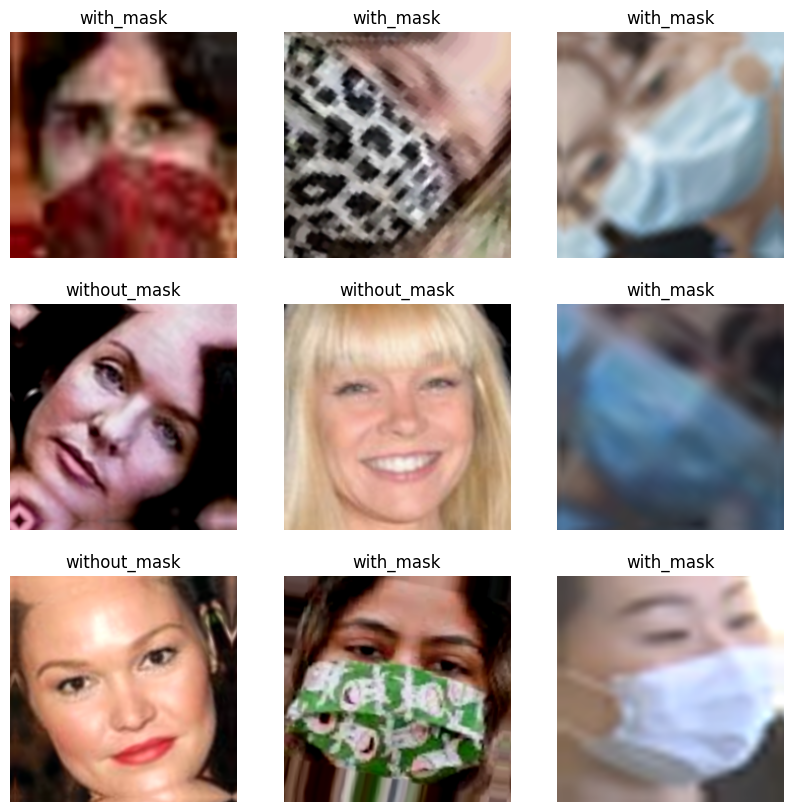

In [12]:
# checking data
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_labels[labels[i]])
    plt.axis("off")

# Modeling

some pre-requisite knowledge
## A. transfer learning
- freeze base layers including batchNormalization layers(appears mostly in image models)
- set inference mode of batchNormalization layers to False
- add custom dense layer

## B. fine-tuning
- unfreeze some top base layers
- set inference mode of batchNormalization layers to False
- add custom dense layer

## C.Batch Normalization
- (BN) layer has two modes:
#### 1.Training mode (training=True)
- Uses batch statistics (mean, variance of current batch)
- Updates moving averages
#### 2.Inference mode (training=False)
- Uses stored moving averages (from pretraining)
- Does NOT update statistics


### Loading EfficientNet Base model

In [13]:
# # weights='imagenet' : load the efficientnet base model with pretrained weights,
# # include_top=False : the top fully connected dense layer will not be included in the base model(so we can add custom layers)
# # input_shape=(224,224,3) : efficientnetv2b0 expects 224x224 RGB images
# # include_preprocessing=False : donot load the preprocessing layer provided by efficientnetv2b0
# base_model = EfficientNetV2B0(weights='imagenet',include_top=False,input_shape=(224,224,3),include_preprocessing=False)

In [14]:
# weights='imagenet' : load the efficientnet base model with pretrained weights,
# include_top=False : the top fully connected dense layer will not be included in the base model(so we can add custom layers)
# input_shape=(224,224,3) : efficientnetb0 expects 224x224 RGB images
base_model = EfficientNetB0(weights='imagenet',include_top=False,input_shape=(224,224,3))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [15]:
# base_model.summary()

## Freeze base layers

In [16]:
for layer in base_model.layers:
  layer.trainable = False

# this prevents base layers including batchNormalization layer from updating its paramaters like weights(beta,gamma)
# but still doesnot freeze moving averages, moving variances
# to do so, keep the BatchNormalization layers in inference mode by passing training=False

## Add custom top dense layer to make a new model

visit this site for : transfer learning and finetuning demo using Sequential(), Model()
- https://keras.io/guides/transfer_learning/

TIP:
- use Sequential(), if NN is linearly stacked
- use Model(), if NN is complex like in transfer learning, fine tuning
- you can also use both in same NN architecture

In [17]:
inputs = tf.keras.Input(shape=(224, 224, 3)) # input layer
# base model
x = base_model(inputs, training=False) # training=False :  BatchNormalization layers in inference mode
# custom classification layer
x = GlobalAveragePooling2D()(x) # why used instead of Flatten???
x = Dense(128, activation='relu')(x)
outputs = Dense(3, activation='softmax')(x) # 3 output nodes for multiclass classification(classes=3)

model = Model(inputs, outputs)

model.compile(optimizer=Adam(learning_rate = 1e-4), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

Q. Why GlobalAveragePooling2D is used instead of Flatten ?
- While flattening a 7x7x512 tensor creates a 25,088-element vector (leading to millions of weights in the subsequent dense layer), GAP reduces this to a 512-element vector, regardless of spatial input size. So, there will be limited no.of weights in the subsequent dense layers reducing the chance of overfitting.

In [18]:
# plot_model(model, show_shapes=True)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,926 (16.07 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## Training the model

In [19]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_accuracy',
    min_delta=0.001,
    patience=5,
    verbose=1
)

model_history = model.fit(
    train_ds,
    epochs=50,
    validation_data = val_ds,
    callbacks = early_stop
)

Epoch 1/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 867s 13s/step - accuracy: 0.8962 - loss: 0.4113 - val_accuracy: 0.9877 - val_loss: 0.1087
Epoch 2/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 62s 920ms/step - accuracy: 0.9728 - loss: 0.1096 - val_accuracy: 0.9877 - val_loss: 0.0539
Epoch 3/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 62s 904ms/step - accuracy: 0.9781 - loss: 0.0743 - val_accuracy: 0.9888 - val_loss: 0.0393
Epoch 4/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 82s 919ms/step - accuracy: 0.9816 - loss: 0.0601 - val_accuracy: 0.9911 - val_loss: 0.0317
Epoch 5/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 61s 917ms/step - accuracy: 0.9821 - loss: 0.0526 - val_accuracy: 0.9911 - val_loss: 0.0280
Epoch 6/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 82s 915ms/step - accuracy: 0.9869 - loss: 0.0431 - val_accuracy: 0.9911 - val_loss: 0.0241
Epoch 7/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 60s 902ms/step - accuracy: 0.9890 - loss: 0.0389 - val_accuracy: 0.9922 - val_loss: 0.0216
Epoch 8/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 60s 898ms/step - accuracy: 0.9907 - loss: 0.0341 - val_accur

# Model dumping

In [20]:
model_path1 = "/content/drive/MyDrive/Colab Notebooks/Projects/face_mask_detection/FaceMaskClassifier.keras"

In [21]:
import pickle as pk

pk.dump(model,open(model_path1,"wb"))

In [22]:
model.save(model_path1)

In [23]:
# loading
model_loaded = load_model(model_path1)

In [24]:
# saving model history also
import json
hist_path = "/content/drive/MyDrive/Colab Notebooks/Projects/face_mask_detection/FaceMaskClassifierHhistory.json"
with open(hist_path,"w") as file:
  json.dump(model_history.history,file)

# loading
with open(hist_path,"r") as file:
  model_history = json.load(file)


# Evaluation

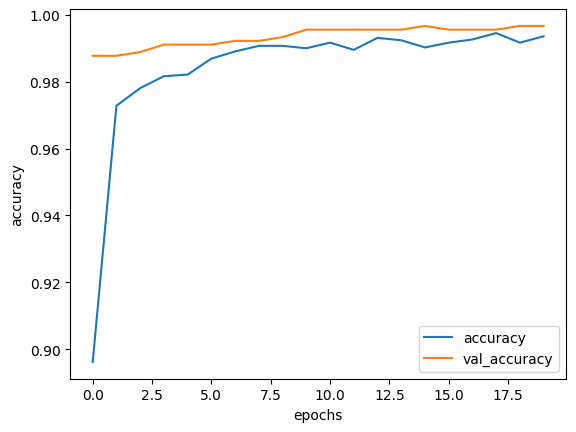

In [25]:
plt.plot(model_history['accuracy'],label='accuracy')
plt.plot(model_history['val_accuracy'],label='val_accuracy')
plt.xlabel("epochs")
plt.ylabel("accuracy")
plt.legend()
plt.show()

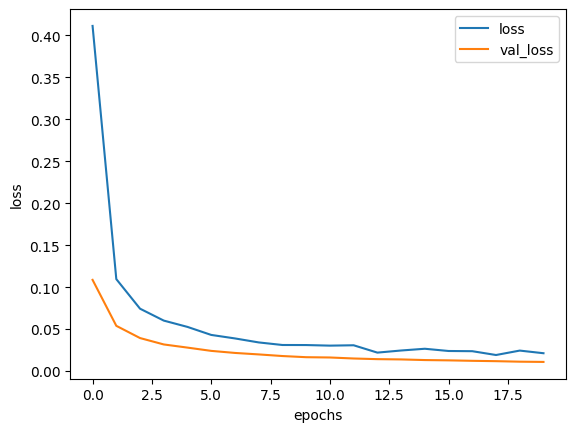

In [26]:
plt.plot(model_history['loss'],label='loss')
plt.plot(model_history['val_loss'],label='val_loss')
plt.xlabel("epochs")
plt.ylabel("loss")
plt.legend()
plt.show()

### Accuracy

In [27]:
# training accuracy and loss
loss,acc = model_loaded.evaluate(train_ds)
print(f"Loss = {loss}")
print(f"Accuracy = {acc}")

66/66 ━━━━━━━━━━━━━━━━━━━━ 72s 890ms/step - accuracy: 0.9967 - loss: 0.0137
Loss = 0.01374782808125019
Accuracy = 0.9966602921485901


In [28]:
# testing accuracy and loss
loss,acc = model_loaded.evaluate(test_ds)
print(f"Loss = {loss}")
print(f"Accuracy = {acc}")

15/15 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.9969 - loss: 0.0107
Loss = 0.01072408352047205
Accuracy = 0.996874988079071


### Classification report

In [29]:
y_pred_prob = model_loaded.predict(test_ds)
y_pred_prob

15/15 ━━━━━━━━━━━━━━━━━━━━ 12s 176ms/step


array([[2.2733158e-03, 9.9753129e-01, 1.9536470e-04],
       [9.9979925e-01, 1.2663729e-04, 7.3954630e-05],
       [9.9747461e-01, 2.4753318e-03, 5.0077258e-05],
       ...,
       [5.3405678e-03, 9.9450052e-01, 1.5880875e-04],
       [9.9998975e-01, 5.8488272e-06, 4.4564158e-06],
       [9.9987435e-01, 9.1496629e-05, 3.4132878e-05]], dtype=float32)

In [30]:
y_pred = np.argmax(y_pred_prob, axis=1)
y_pred

array([1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1,
       0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0,
       1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0,
       1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1,
       0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1,
       0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0,
       1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0,
       1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0,
       1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1,

In [31]:
# predicted classes
y_pred_classes = [class_labels[i] for i in y_pred]
print(y_pred_classes)

['without_mask', 'with_mask', 'with_mask', 'without_mask', 'with_mask', 'without_mask', 'with_mask', 'with_mask', 'without_mask', 'with_mask', 'without_mask', 'with_mask', 'without_mask', 'with_mask', 'with_mask', 'with_mask', 'with_mask', 'without_mask', 'without_mask', 'with_mask', 'with_mask', 'without_mask', 'with_mask', 'without_mask', 'without_mask', 'with_mask', 'without_mask', 'with_mask', 'without_mask', 'with_mask', 'with_mask', 'with_mask', 'without_mask', 'without_mask', 'with_mask', 'without_mask', 'with_mask', 'with_mask', 'without_mask', 'with_mask', 'without_mask', 'without_mask', 'without_mask', 'with_mask', 'without_mask', 'without_mask', 'with_mask', 'with_mask', 'without_mask', 'without_mask', 'with_mask', 'without_mask', 'without_mask', 'without_mask', 'with_mask', 'with_mask', 'without_mask', 'with_mask', 'without_mask', 'without_mask', 'without_mask', 'without_mask', 'with_mask', 'with_mask', 'without_mask', 'with_mask', 'without_mask', 'with_mask', 'without_mask

In [32]:
y_true = []

for images, labels in test_ds:
    y_true.extend(labels.numpy())

y_true = np.array(y_true)
y_true

array([1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1,
       0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0,
       1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0,
       1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1,
       0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1,
       0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0,
       1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0,
       1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0,
       1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1,
       0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 1,

In [33]:
# true classes
y_true_classes = [class_labels[i] for i in y_true]
print(y_true_classes)

['without_mask', 'with_mask', 'with_mask', 'without_mask', 'with_mask', 'without_mask', 'with_mask', 'with_mask', 'without_mask', 'with_mask', 'without_mask', 'with_mask', 'without_mask', 'with_mask', 'with_mask', 'with_mask', 'with_mask', 'without_mask', 'without_mask', 'with_mask', 'with_mask', 'without_mask', 'with_mask', 'without_mask', 'without_mask', 'with_mask', 'without_mask', 'with_mask', 'without_mask', 'with_mask', 'with_mask', 'with_mask', 'without_mask', 'without_mask', 'with_mask', 'without_mask', 'with_mask', 'with_mask', 'without_mask', 'with_mask', 'without_mask', 'without_mask', 'without_mask', 'with_mask', 'without_mask', 'without_mask', 'with_mask', 'with_mask', 'without_mask', 'without_mask', 'with_mask', 'without_mask', 'without_mask', 'without_mask', 'with_mask', 'with_mask', 'without_mask', 'with_mask', 'without_mask', 'without_mask', 'without_mask', 'without_mask', 'with_mask', 'with_mask', 'without_mask', 'with_mask', 'without_mask', 'with_mask', 'without_mask

In [34]:
print(classification_report(y_true_classes, y_pred_classes))

              precision    recall  f1-score   support

   with_mask       1.00      1.00      1.00       483
without_mask       1.00      1.00      1.00       477

    accuracy                           1.00       960
   macro avg       1.00      1.00      1.00       960
weighted avg       1.00      1.00      1.00       960



### Confusion Matrix

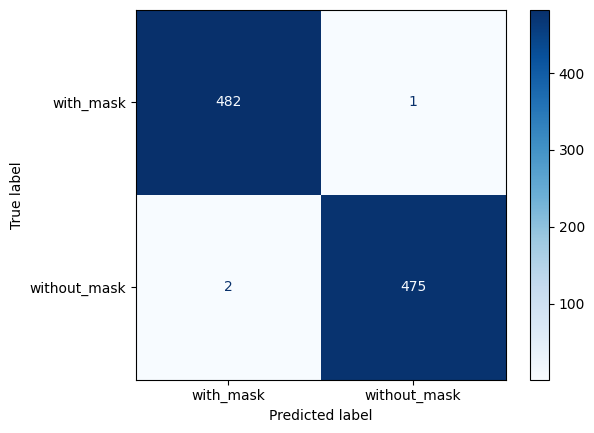

In [35]:
cm = confusion_matrix(y_true_classes,y_pred_classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)
disp.plot(cmap=plt.cm.Blues)
plt.show()

# Testing

In [36]:
class_labels = ['with_mask', 'without_mask']
img = Image.open("/content/drive/MyDrive/Colab Notebooks/Projects/face_mask_detection/Dataset/without_mask/1.png")

img = img.resize((224,224))
img_array = np.array(img)

# img_array = np.expand_dims(img_array, axis=0) / 255.0 # converts shape to (1,224,224,3) and applies min max scaling
img_array = np.expand_dims(img_array, axis=0)
img_array = preprocess_input(img_array)  # Correct
# The preprocessing logic has been included in the efficientnet model implementation.
# Users are no longer required to call this method to normalize the input data.
# This method does nothing and only kept as a placeholder to align the API surface between old and new version of model.
print(img_array.shape)

prob = model_loaded.predict(img_array)
print(prob)
predicted_class_index = np.argmax(prob) # returns index of that has max value
print("Predicted class:", class_labels[predicted_class_index])

(1, 224, 224, 3)
1/1 ━━━━━━━━━━━━━━━━━━━━ 20s 20s/step
[[2.8718361e-03 9.9707890e-01 4.9315597e-05]]
Predicted class: without_mask
